In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
print(os.getcwd())

C:\Users\Meenakshi


In [3]:
import pandas as pd
df = pd.read_csv(r"C:\Users\Meenakshi\Downloads\service_assurance_banking_cross_border_payment_delays_80k.csv")

In [4]:
df.head()

,Transaction_ID,Routing_Hop_Count,FX_Conversion_Required,Target_Currency_Liquidity,Historical_Path_Latency_Hrs,Predicted_Total_Delay_Hrs,Settlement_SLA_Status
0,TXN_SWIFT_000001,3,1,High,11.68,50.34,CRITICAL_SLA_Breach
1,TXN_SWIFT_000002,5,1,High,5.14,51.77,CRITICAL_SLA_Breach
2,TXN_SWIFT_000003,1,1,High,5.43,13.85,SUCCESS_Within_SLA
3,TXN_SWIFT_000004,3,1,High,4.23,28.56,WARNING_Delayed_Settlement
4,TXN_SWIFT_000005,2,0,High,10.41,36.53,WARNING_Delayed_Settlement


In [5]:
df.shape

(80000, 7)

In [6]:
df.columns

Index(['Transaction_ID', 'Routing_Hop_Count', 'FX_Conversion_Required',
       'Target_Currency_Liquidity', 'Historical_Path_Latency_Hrs',
       'Predicted_Total_Delay_Hrs', 'Settlement_SLA_Status'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Transaction_ID               80000 non-null  str    
 1   Routing_Hop_Count            80000 non-null  int64  
 2   FX_Conversion_Required       80000 non-null  int64  
 3   Target_Currency_Liquidity    80000 non-null  str    
 4   Historical_Path_Latency_Hrs  80000 non-null  float64
 5   Predicted_Total_Delay_Hrs    80000 non-null  float64
 6   Settlement_SLA_Status        80000 non-null  str    
dtypes: float64(2), int64(2), str(3)
memory usage: 4.3 MB


In [8]:
df.isnull().sum()

Transaction_ID                 0
Routing_Hop_Count              0
FX_Conversion_Required         0
Target_Currency_Liquidity      0
Historical_Path_Latency_Hrs    0
Predicted_Total_Delay_Hrs      0
Settlement_SLA_Status          0
dtype: int64

In [9]:
df.describe()

,Routing_Hop_Count,FX_Conversion_Required,Historical_Path_Latency_Hrs,Predicted_Total_Delay_Hrs
count,80000.000000,80000.000000,80000.000000,80000.000000
mean,2.201513,0.600762,6.252708,29.750245
std,1.119607,0.489745,3.316950,16.500577
min,1.000000,0.000000,0.500000,3.720000
25%,1.000000,0.000000,3.390000,17.210000
50%,2.000000,1.000000,6.240000,26.300000
75%,3.000000,1.000000,9.130000,37.990000
max,5.000000,1.000000,12.000000,131.680000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df=df.drop_duplicates()

In [12]:
df.shape

(80000, 7)

In [13]:
df["Target_Currency_Liquidity"].unique()

<StringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str

In [14]:
df.head(10)

,Transaction_ID,Routing_Hop_Count,FX_Conversion_Required,Target_Currency_Liquidity,Historical_Path_Latency_Hrs,Predicted_Total_Delay_Hrs,Settlement_SLA_Status
0,TXN_SWIFT_000001,3,1,High,11.68,50.34,CRITICAL_SLA_Breach
1,TXN_SWIFT_000002,5,1,High,5.14,51.77,CRITICAL_SLA_Breach
2,TXN_SWIFT_000003,1,1,High,5.43,13.85,SUCCESS_Within_SLA
3,TXN_SWIFT_000004,3,1,High,4.23,28.56,WARNING_Delayed_Settlement
4,TXN_SWIFT_000005,2,0,High,10.41,36.53,WARNING_Delayed_Settlement
5,TXN_SWIFT_000006,5,0,High,4.91,61.51,CRITICAL_SLA_Breach
6,TXN_SWIFT_000007,2,0,Medium,1.78,11.23,SUCCESS_Within_SLA
7,TXN_SWIFT_000008,2,1,Low,4.17,69.61,CRITICAL_SLA_Breach
8,TXN_SWIFT_000009,2,0,Medium,7.79,32.24,WARNING_Delayed_Settlement
9,TXN_SWIFT_000010,2,0,High,5.12,22.27,SUCCESS_Within_SLA


In [15]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Target_Currency_Liquidity'] = le.fit_transform(df['Target_Currency_Liquidity'])

In [16]:
print(df.dtypes)

Transaction_ID                     str
Routing_Hop_Count                int64
FX_Conversion_Required           int64
Target_Currency_Liquidity        int64
Historical_Path_Latency_Hrs    float64
Predicted_Total_Delay_Hrs      float64
Settlement_SLA_Status              str
dtype: object


In [17]:
df.head()

,Transaction_ID,Routing_Hop_Count,FX_Conversion_Required,Target_Currency_Liquidity,Historical_Path_Latency_Hrs,Predicted_Total_Delay_Hrs,Settlement_SLA_Status
0,TXN_SWIFT_000001,3,1,0,11.68,50.34,CRITICAL_SLA_Breach
1,TXN_SWIFT_000002,5,1,0,5.14,51.77,CRITICAL_SLA_Breach
2,TXN_SWIFT_000003,1,1,0,5.43,13.85,SUCCESS_Within_SLA
3,TXN_SWIFT_000004,3,1,0,4.23,28.56,WARNING_Delayed_Settlement
4,TXN_SWIFT_000005,2,0,0,10.41,36.53,WARNING_Delayed_Settlement


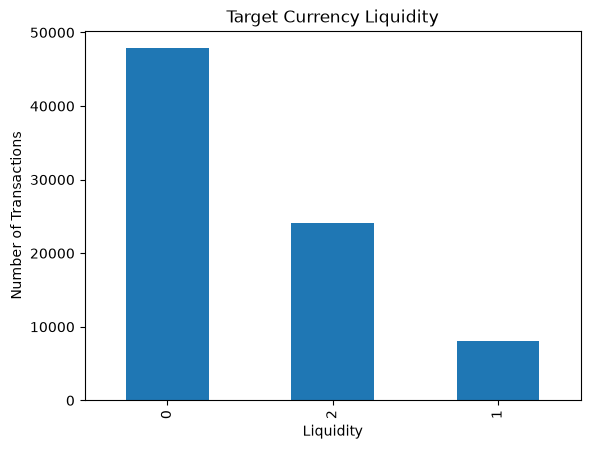

In [18]:
import matplotlib.pyplot as plt

df["Target_Currency_Liquidity"].value_counts().plot(kind="bar")

plt.title("Target Currency Liquidity")
plt.xlabel("Liquidity")
plt.ylabel("Number of Transactions")
plt.show()

### Description

This bar chart shows the distribution of transactions based on Target Currency Liquidity. The x-axis represents the liquidity categories (High, Medium, and Low), and the y-axis represents the number of transactions. From the graph, High liquidity has the highest number of transactions, followed by Medium and Low liquidity. This indicates that most cross-border payment transactions are made using highly liquid currencies, which generally allows faster and smoother payment processing.

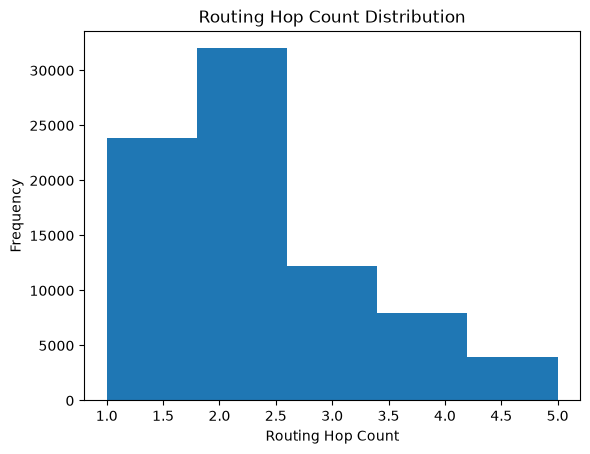

In [19]:
import matplotlib.pyplot as plt

plt.hist(df["Routing_Hop_Count"], bins=5)

plt.title("Routing Hop Count Distribution")
plt.xlabel("Routing Hop Count")
plt.ylabel("Frequency")
plt.show()

### Description

This histogram shows the distribution of the **Routing Hop Count** feature in the dataset. The x-axis represents the routing hop count, and the y-axis represents the frequency of transactions. Most transactions have **2 routing hops**, followed by **1 routing hop**. As the routing hop count increases, the number of transactions decreases, indicating that higher routing hop counts are less common.

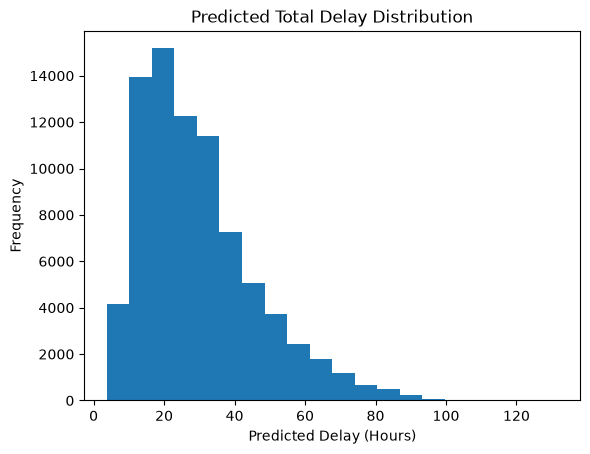

In [20]:
import matplotlib.pyplot as plt

plt.hist(df["Predicted_Total_Delay_Hrs"], bins=20)

plt.title("Predicted Total Delay Distribution")
plt.xlabel("Predicted Delay (Hours)")
plt.ylabel("Frequency")
plt.show()

### Description

This histogram shows the distribution of the Predicted Total Delay (Hours) for cross-border payment transactions. The x-axis represents the predicted delay in hours, and the y-axis represents the frequency (number of transactions). Most transactions have a predicted delay between 10 and 40 hours. As the predicted delay increases, the number of transactions decreases. Only a few transactions have very high predicted delays above 80 hours. This indicates that most payments are predicted to experience low to moderate delays, while very long delays are uncommon.

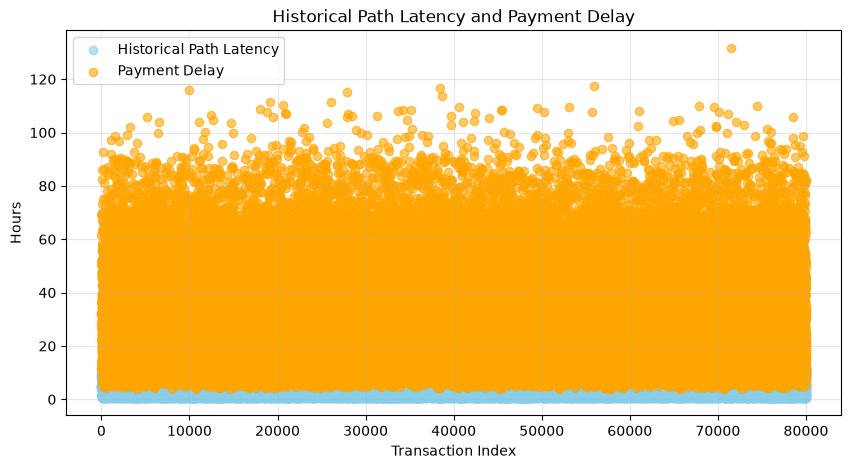

In [21]:
plt.figure(figsize=(10,5))

# Historical Path Latency
plt.scatter(df.index,
            df["Historical_Path_Latency_Hrs"],
            color="skyblue",
            alpha=0.6,
            label="Historical Path Latency")

# Payment Delay
plt.scatter(df.index,
            df["Predicted_Total_Delay_Hrs"],
            color="orange",
            alpha=0.6,
            label="Payment Delay")

plt.xlabel("Transaction Index")
plt.ylabel("Hours")
plt.title("Historical Path Latency and Payment Delay")
plt.legend()

plt.grid(True, alpha=0.3)
plt.show()

### Description

This graph compares the Historical Path Latency and Payment Delay for the payment transactions. Each point represents a transaction, and different colours are used to distinguish the two variables. The blue points represent the historical path latency, while the orange points represent the payment delay. The graph helps us visually compare the variation in latency and payment delay across different transactions.

<Figure size 800x500 with 0 Axes>

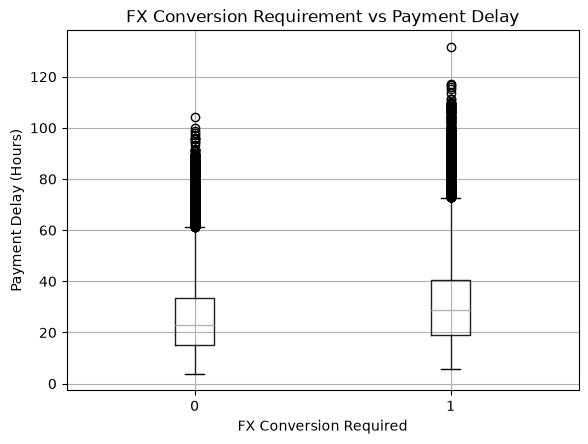

In [22]:
plt.figure(figsize=(8,5))

df.boxplot(column="Predicted_Total_Delay_Hrs",
           by="FX_Conversion_Required")

plt.xlabel("FX Conversion Required")
plt.ylabel("Payment Delay (Hours)")
plt.title("FX Conversion Requirement vs Payment Delay")

plt.suptitle("")
plt.show()

### Description

This box plot compares the distribution of payment delays based on whether foreign exchange (FX) conversion is required. Here, **0 represents that FX conversion is not required**, while **1 represents that FX conversion is required**.

The graph shows that transactions requiring FX conversion generally have a higher median payment delay than transactions that do not require FX conversion. It also shows the variation and outliers in payment delays for both categories. Therefore, FX conversion requirement appears to be an important factor associated with payment delay.

<Figure size 800x500 with 0 Axes>

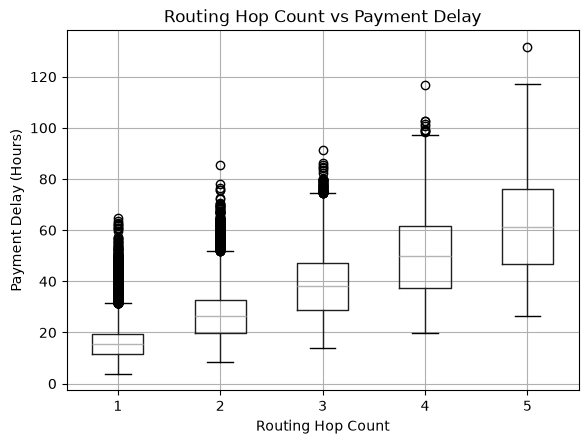

In [23]:
plt.figure(figsize=(8,5))

df.boxplot(column="Predicted_Total_Delay_Hrs",
           by="Routing_Hop_Count")

plt.xlabel("Routing Hop Count")
plt.ylabel("Payment Delay (Hours)")
plt.title("Routing Hop Count vs Payment Delay")

plt.suptitle("")
plt.show()


### Description

This box plot shows the relationship between Routing Hop Count and Payment Delay. Each box represents the distribution of payment delays for a particular number of routing hops. The line inside each box represents the median payment delay, while the box represents the middle 50% of the observations. The whiskers show the typical range, and the points beyond the whiskers represent outliers.

The graph shows an increasing trend in the median payment delay as the routing hop count increases. Transactions with more routing hops generally experience higher payment delays. Therefore, routing hop count appears to be an important factor associated with cross-border payment delay.

<Figure size 800x500 with 0 Axes>

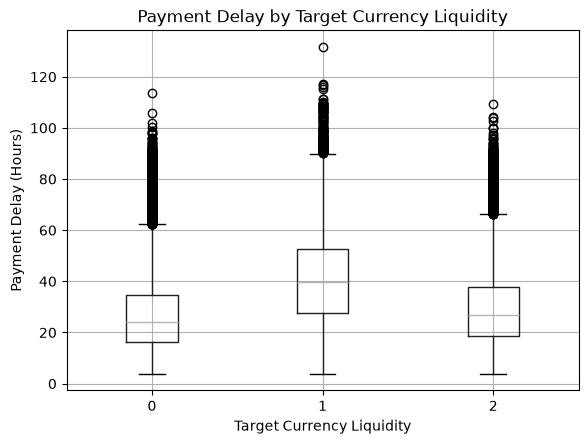

In [24]:
plt.figure(figsize=(8,5))

df.boxplot(column="Predicted_Total_Delay_Hrs",
           by="Target_Currency_Liquidity")

plt.xlabel("Target Currency Liquidity")
plt.ylabel("Payment Delay (Hours)")
plt.title("Payment Delay by Target Currency Liquidity")

plt.suptitle("")
plt.show()

### Description

This box plot shows the distribution of payment delays for different levels of Target Currency Liquidity. The x-axis represents the liquidity levels (0, 1, and 2), while the y-axis represents payment delay in hours.

Each box represents the middle 50% of payment delays for that liquidity level. The line inside the box represents the median payment delay, while the whiskers show the typical range of values. The individual points beyond the whiskers represent outliers, which are transactions with unusually high payment delays.

From the graph, liquidity level 1 has a higher median payment delay compared with liquidity levels 0 and 2. Liquidity level 0 has a lower median delay, while liquidity level 2 has a median delay between levels 0 and 1. This shows that payment delay varies across different levels of target currency liquidity.

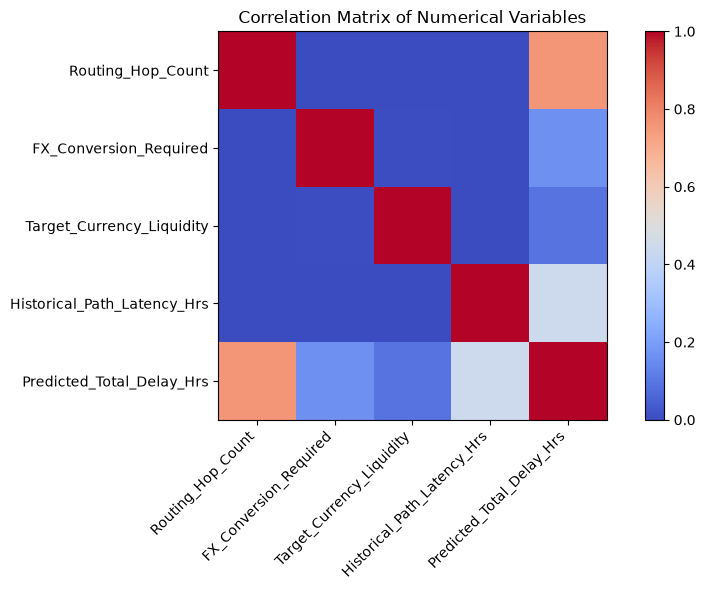

In [25]:
plt.figure(figsize=(9,6))

correlation = df.select_dtypes(include=np.number).corr()

plt.imshow(correlation, cmap="coolwarm", interpolation="nearest")

plt.colorbar()

plt.xticks(range(len(correlation.columns)),
           correlation.columns,
           rotation=45,
           ha="right")

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

plt.title("Correlation Matrix of Numerical Variables")

plt.tight_layout()
plt.show()

### Description

This correlation matrix shows the relationship between the numerical variables in the cross-border payment dataset. Each cell represents the correlation between two variables. The colour and intensity indicate the strength of the relationship.

A value closer to 1 indicates a strong positive relationship, while a value closer to 0 indicates a weak relationship. The diagonal cells show a correlation of 1 because each variable is perfectly correlated with itself.

The matrix helps identify which input variables have stronger relationships with payment delay and with each other. This analysis is useful for understanding the dataset and selecting relevant features for the machine learning model.

In [26]:
X = df[['Routing_Hop_Count',
        'FX_Conversion_Required',
        'Target_Currency_Liquidity',
        'Historical_Path_Latency_Hrs']]

y = df['Predicted_Total_Delay_Hrs']

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [30]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[12.52, 2.67, 1.45, 7.33]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,29.78
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[254.1 ,253.21,252.79,251.82]"


In [31]:
y_pred = model.predict(X_test)

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 5.379462678114281
MSE: 53.46361768427919
RMSE: 7.311881952293759
R2 Score: 0.8020483571849697


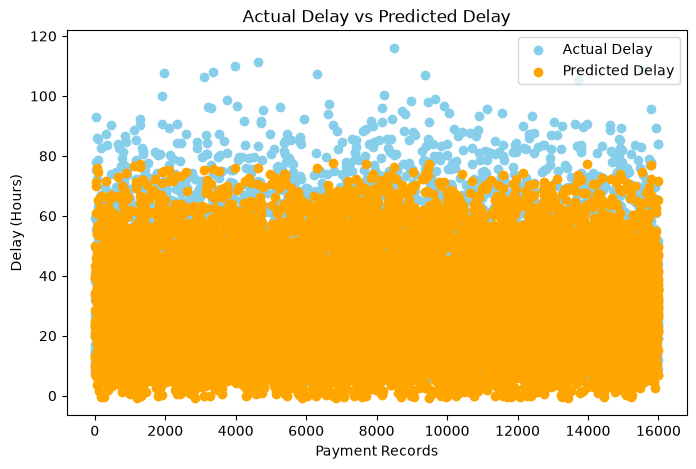

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(range(len(y_test)), y_test, label="Actual Delay", color="skyblue")
plt.scatter(range(len(y_pred)), y_pred, label="Predicted Delay", color="orange")

plt.xlabel("Payment Records")
plt.ylabel("Delay (Hours)")
plt.title("Actual Delay vs Predicted Delay")

plt.legend()
plt.show()

### Actual Delay vs Predicted Delay

This graph compares the actual payment delay values from the dataset with the delay values predicted by the machine learning model.

- Sky blue points represent **Actual Delay**, which are the real delay hours recorded in the dataset.
- Orange points represent **Predicted Delay**, which are the delay hours estimated by the trained model.
- The comparison helps to understand how closely the model predictions match the actual payment delays.
- A smaller difference between actual and predicted values indicates better model performance.
- This visualization helps evaluate the accuracy of the model in predicting cross-border payment delays.

In [34]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print(coefficients)

                       Feature  Coefficient
0            Routing_Hop_Count    12.520937
1       FX_Conversion_Required     2.674324
2    Target_Currency_Liquidity     1.445144
3  Historical_Path_Latency_Hrs     7.328686


In [35]:
from sklearn.tree import DecisionTreeRegressor

model =  DecisionTreeRegressor()
model.fit(X_train, y_train)

,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_node

In [36]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Decision Tree Regressor")
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("MSE:", mean_squared_error(y_test, y_pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))
print("R2 Score:", r2_score(y_test, y_pred_dt))

Decision Tree Regressor
MAE: 3.473585797205603
MSE: 23.067659101956075
RMSE: 4.802880292278382
R2 Score: 0.9145908710836829


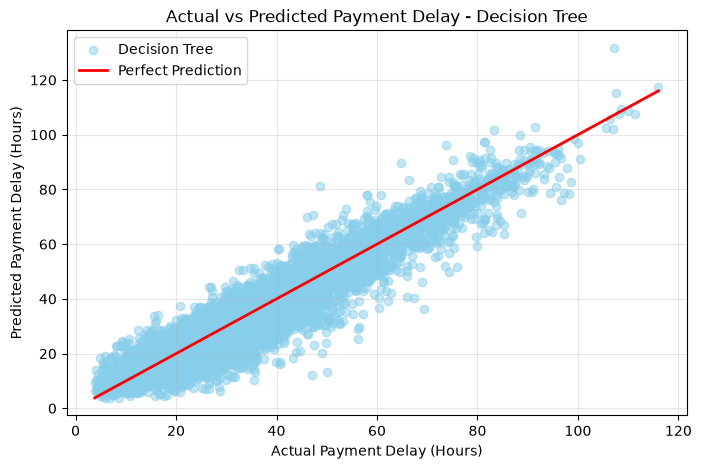

In [37]:
y_pred_dt = model.predict(X_test)

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred_dt,
            color="skyblue",
            alpha=0.5,
            label="Decision Tree")

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red",
         linewidth=2,
         label="Perfect Prediction")

plt.xlabel("Actual Payment Delay (Hours)")
plt.ylabel("Predicted Payment Delay (Hours)")
plt.title("Actual vs Predicted Payment Delay - Decision Tree")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Description

This scatter plot compares the actual payment delay with the payment delay predicted by the Decision Tree Regression model. The x-axis represents the actual payment delay in hours, while the y-axis represents the predicted payment delay in hours.

Each blue point represents a payment transaction. The red diagonal line represents perfect prediction, where the predicted delay is equal to the actual delay. Points closer to this line indicate more accurate predictions, while points farther from the line represent prediction errors.

The graph shows a clear positive relationship between actual and predicted payment delays, indicating that the Decision Tree model is able to capture the relationship between the input features and payment delay.

In [38]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [39]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Regressor")
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("MSE:", mean_squared_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R2 Score:", r2_score(y_test, y_pred_rf))

Random Forest Regressor
MAE: 3.3107907487410246
MSE: 20.615440069177676
RMSE: 4.54042289541158
R2 Score: 0.9236703312307186


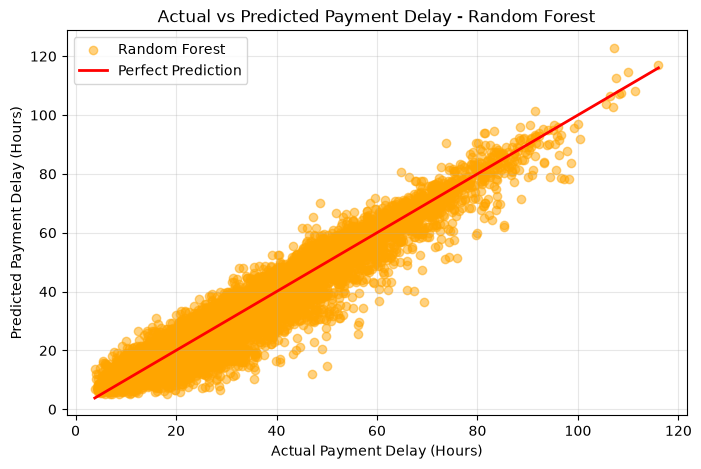

In [40]:
y_pred_rf = rf.predict(X_test)

plt.figure(figsize=(8,5))

plt.scatter(
    y_test,
    y_pred_rf,
    color="orange",
    alpha=0.5,
    label="Random Forest"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Payment Delay (Hours)")
plt.ylabel("Predicted Payment Delay (Hours)")
plt.title("Actual vs Predicted Payment Delay - Random Forest")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Description

This scatter plot compares the actual payment delay with the payment delay predicted by the Random Forest Regression model. The x-axis represents the actual payment delay in hours, while the y-axis represents the predicted payment delay in hours.

Each orange point represents a payment transaction. The red diagonal line represents perfect prediction, where the predicted delay is equal to the actual delay. Points closer to the red line indicate more accurate predictions, while points farther from the line indicate prediction errors.

The graph shows a strong positive relationship between the actual and predicted payment delays, as most of the points are distributed around the perfect prediction line. This indicates that the Random Forest model is able to predict the payment delay reasonably well.

In [42]:
from sklearn.ensemble import GradientBoostingRegressor

In [43]:
gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

In [44]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)

print("Gradient Boosting Regressor")
print("MAE:", mean_absolute_error(y_test, y_pred_gb))
print("MSE:", mean_squared_error(y_test, y_pred_gb))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_gb)))
print("R2 Score:", r2_score(y_test, y_pred_gb))

Gradient Boosting Regressor
MAE: 3.046287180178536
MSE: 16.900952468662606
RMSE: 4.111076801601085
R2 Score: 0.937423402096221


In [45]:
y_pred_gb = gb_model.predict(X_test)

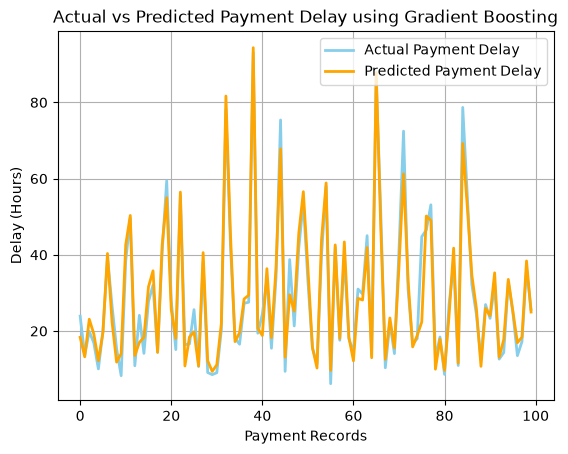

In [56]:
plt.plot(y_test.values[:100], label="Actual Payment Delay", color="skyblue", linewidth=2)
plt.plot(y_pred_gb[:100], label="Predicted Payment Delay", color="orange", linewidth=2)

plt.title("Actual vs Predicted Payment Delay using Gradient Boosting")
plt.xlabel("Payment Records")
plt.ylabel("Delay (Hours)")
plt.legend()
plt.grid(True)
plt.show()

### Actual vs Predicted Payment Delay using Gradient Boosting

This graph compares the actual payment delay values with the delay values predicted by the Gradient Boosting Regression model.

- The **sky blue line represents Actual Payment Delay**, which shows the real delay hours from the test dataset.
- The **orange line represents Predicted Payment Delay**, which shows the delay hours predicted by the Gradient Boosting model.
- The comparison between both lines helps to understand how accurately the model predicts payment delays.
- When the predicted values are closer to the actual values, it indicates better model performance.
- The Gradient Boosting model achieved an **R² score of 0.937423**, showing that it can effectively predict cross-border payment delays.

In [47]:
from sklearn.ensemble import ExtraTreesRegressor

et = ExtraTreesRegressor(
    n_estimators=100,
    random_state=42
)

et.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split ind

In [48]:
from sklearn.ensemble import ExtraTreesRegressor

et = ExtraTreesRegressor(n_estimators=100, random_state=42)
et.fit(X_train, y_train)

y_pred_et = et.predict(X_test)

print("Extra Trees Regressor")
print("MAE:", mean_absolute_error(y_test, y_pred_et))
print("MSE:", mean_squared_error(y_test, y_pred_et))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_et)))
print("R2 Score:", r2_score(y_test, y_pred_et))

Extra Trees Regressor
MAE: 3.422744730168456
MSE: 22.302948791537375
RMSE: 4.722599791591214
R2 Score: 0.9174222481730318


In [49]:
y_pred_et = et.predict(X_test)

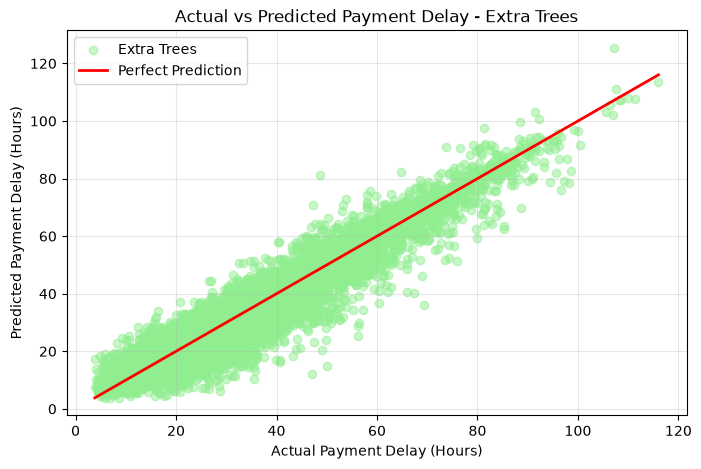

In [50]:
plt.figure(figsize=(8,5))

plt.scatter(
    y_test,
    y_pred_et,
    color="lightgreen",
    alpha=0.5,
    label="Extra Trees"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Payment Delay (Hours)")
plt.ylabel("Predicted Payment Delay (Hours)")
plt.title("Actual vs Predicted Payment Delay - Extra Trees")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Description:
The scatter plot shows the relationship between the actual payment delay and the delay predicted by the Extra Trees Regressor.

- The **X-axis** represents the actual payment delay in hours.
- The **Y-axis** represents the predicted payment delay in hours.
- The **green points** represent the predictions made by the Extra Trees model.
- The **red diagonal line** represents perfect prediction, where actual delay equals predicted delay.
- Points closer to the red line indicate more accurate predictions.
- The points are mostly concentrated around the diagonal line, showing that the Extra Trees model predicts payment delays reasonably well.
- Some points are farther from the line, indicating prediction errors or variations in the data.

**Conclusion:** The Extra Trees Regressor shows a good relationship between actual and predicted payment delays and can effectively predict cross-border payment delays.

In [51]:
results = {
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "Extra Trees"
    ],
    "R2 Score": [
        r2_score(y_test, y_pred),
        r2_score(y_test, y_pred_dt),
        r2_score(y_test, y_pred_rf),
        r2_score(y_test, y_pred_gb),
        r2_score(y_test, y_pred_et)
    ]
}

comparison = pd.DataFrame(results)
print(comparison)

               Model  R2 Score
0  Linear Regression  0.802048
1      Decision Tree  0.914602
2      Random Forest  0.923670
3  Gradient Boosting  0.937423
4        Extra Trees  0.917422


In [52]:
comparison = comparison.sort_values(by="R2 Score", ascending=False)
print(comparison)

               Model  R2 Score
3  Gradient Boosting  0.937423
2      Random Forest  0.923670
4        Extra Trees  0.917422
1      Decision Tree  0.914602
0  Linear Regression  0.802048


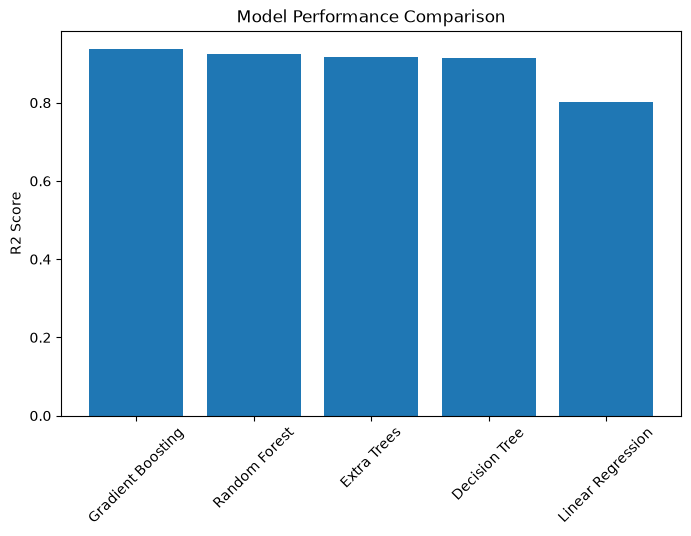

In [53]:
plt.figure(figsize=(8,5))
plt.bar(comparison["Model"], comparison["R2 Score"])
plt.xticks(rotation=45)
plt.ylabel("R2 Score")
plt.title("Model Performance Comparison")
plt.show()

### Graph Description

The above bar chart compares the **R² Scores** of the five regression models used for predicting cross-border payment delays. The **Gradient Boosting Regression** model achieved the highest **R² Score (0.9374)**, indicating the best prediction accuracy among all the models. It is followed by **Random Forest Regression (0.9238)**, **Extra Trees Regression (0.9174)**, **Decision Tree Regression (0.9149)**, and **Linear Regression (0.8020)**.

A higher R² Score indicates better model performance. Therefore, **Gradient Boosting Regression** was selected as the final model because it provides the most accurate and reliable predictions for this dataset.

In [54]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": gb.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)

print(importance)

                       Feature  Importance
0            Routing_Hop_Count    0.623018
3  Historical_Path_Latency_Hrs    0.253677
2    Target_Currency_Liquidity    0.083276
1       FX_Conversion_Required    0.040029


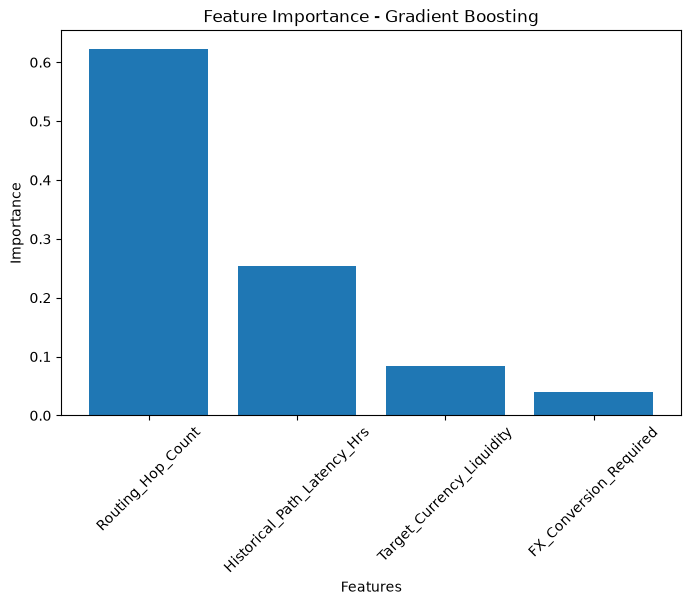

In [55]:
plt.figure(figsize=(8,5))
plt.bar(importance["Feature"], importance["Importance"])
plt.xticks(rotation=45)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance - Gradient Boosting")
plt.show()

### Description

The feature importance graph shows how much each feature contributes to the Gradient Boosting model.

- **Routing_Hop_Count** has the highest importance (~0.62), making it the most influential feature.
- **Historical_Path_Latency_Hrs** is the second most important feature (~0.24).
- **Target_Currency_Liquidity** has lower importance (~0.06).
- **FX_Conversion_Required** has the least importance (~0.01).

**Conclusion:** The model mainly depends on **Routing_Hop_Count** and **Historical_Path_Latency_Hrs** to predict cross-border payment delays.

### Conclusion

Five regression models were trained and evaluated using **MAE, MSE, RMSE, and R² Score** to predict cross-border payment delays.

The obtained **R² Scores** are:

- **Linear Regression:** 0.8020
- **Decision Tree Regression:** 0.9149
- **Random Forest Regression:** 0.9238
- **Gradient Boosting Regression:** 0.9374
- **Extra Trees Regression:** 0.9174

Among all the models, **Gradient Boosting Regression** achieved the highest **R² Score (0.9374)**, indicating the best prediction performance. Therefore, it was selected as the final model for predicting cross-border payment delays.

The selected model can help financial institutions identify transactions that are likely to be delayed, improve operational efficiency, support timely settlement of payments, and enhance customer satisfaction.